# Laboratorio 01 · Visualización de campo escalar
**De un número por punto a mapas de colores e isolíneas**

Universidad Nacional del Altiplano – Puno · Escuela Profesional de Ingeniería de Sistemas · Visualización de Datos  
Estudiante: Franco Abondanshieri Arela Mamani · 25 de noviembre de 2026  
Repositorio: https://github.com/Abondanshieri/vd-lab01-campo-escalar

## 1. Propósito y comprensión del dato

El laboratorio tuvo como propósito comprender qué es un campo escalar y cómo un único valor por punto se representa mediante colores e isolíneas.

Un campo escalar asigna **un solo número a cada posición del espacio**. En este caso el número fue una temperatura simulada en °C: los ejes X e Y indicaron *dónde* se midió y el color indicó *cuánto* se midió. La fórmula empleada es un ejemplo didáctico —una «mancha» de calor con forma de campana en el centro—, no una medición meteorológica real.

## 2. Entorno de ejecución

El cuaderno se ejecutó de forma local con un kernel de Jupyter (Python 3.12) usando exactamente el código de la guía, que solo depende de NumPy y Matplotlib y, por tanto, corre igual en Google Colab. Cada bloque numerado ocupó una celda propia y los bloques se ejecutaron en orden, porque los posteriores reutilizan variables de los anteriores. La celda siguiente solo registró las versiones empleadas, para dejar constancia de la reproducibilidad.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110          # nitidez de las figuras exportadas
print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python    : 3.12.10
NumPy     : 2.4.6
Matplotlib: 3.11.2


## 3. Actividades guiadas

### Bloque 1. Preparar el entorno y crear una grilla

**Qué se hizo.** Se construyó la «tabla de lugares» sobre la que después se asignarían temperaturas: 25 valores para X y 25 para Y, combinados con `np.meshgrid`, dieron 25 × 25 = 625 posiciones. Hasta aquí no existía ninguna temperatura.

In [2]:
import numpy as np                 # Permite calcular con arreglos y matrices
import matplotlib.pyplot as plt    # Permite generar gráficos

# Generamos 25 posiciones horizontales y 25 verticales
x = np.linspace(-5, 5, 25)       # Valores desde -5 hasta 5
y = np.linspace(-5, 5, 25)       # Valores desde -5 hasta 5

# Combinamos cada valor de X con cada valor de Y
X, Y = np.meshgrid(x, y)

print("Forma de X:", X.shape)
print("Total de posiciones:", X.size)
print("Posición del centro:", X[12, 12], Y[12, 12])

Forma de X: (25, 25)
Total de posiciones: 625
Posición del centro: 0.0 0.0


**Resultado observado.** La consola mostró la forma `(25, 25)`, 625 posiciones y el centro en `(0.0, 0.0)`. Que el índice 12 cayera exactamente en el origen no fue casualidad: con 25 puntos (un número impar) el punto central de la grilla coincide con el 0 del intervalo [−5, 5].

**Comprobación del aprendizaje.** El resultado representa la malla de 625 lugares de medición, y la variable que controla su tamaño es el número de puntos de `np.linspace` (25 por eje).

### Bloque 2. Asignar una temperatura a cada punto

**Qué se hizo.** Se evaluó la fórmula `T = 20 + 12·exp(−(X² + Y²)/8)` sobre toda la grilla a la vez, aprovechando que NumPy opera elemento a elemento. El término exponencial vale 1 en el origen y se acerca a 0 al alejarse, de modo que la temperatura pasa de 20 + 12 = 32 °C en el centro a 20 °C lejos de él.

In [3]:
# Un valor de temperatura para cada posición
T = 20 + 12 * np.exp(-(X**2 + Y**2) / 8)

print("Forma del campo escalar:", T.shape)
print("Temperatura en el centro:", round(T[12, 12], 2), "°C")
print("Temperatura mínima:", round(T.min(), 2), "°C")
print("Temperatura máxima:", round(T.max(), 2), "°C")

# Visualizamos los números de una pequeña zona
print("Temperaturas de la zona central:")
print(np.round(T[11:14, 11:14], 1))

Forma del campo escalar: (25, 25)
Temperatura en el centro: 32.0 °C
Temperatura mínima: 20.02 °C
Temperatura máxima: 32.0 °C
Temperaturas de la zona central:
[[31.5 31.7 31.5]
 [31.7 32.  31.7]
 [31.5 31.7 31.5]]


**Resultado observado.** Se obtuvo un arreglo `(25, 25)` con 32,0 °C en el centro, un máximo de 32,0 °C y un mínimo de 20,02 °C en las esquinas, que no llega a 20 exactamente porque la campana nunca se anula del todo (a distancia 5√2 el exponencial aún vale 0,0019). La submatriz central 3 × 3 mostró 32,0 en el medio, 31,7 en los vecinos inmediatos y 31,5 en las diagonales: la simetría radial del campo ya se leía en los números.

**Comprobación del aprendizaje.** El resultado es la temperatura simulada de cada una de las 625 posiciones, y la variable que lo controla es la distancia al centro `X² + Y²`, que decide cuánto se atenúa el término de 12 °C.

### Bloque 3. Convertir los números en un mapa de colores

**Qué se hizo.** Se pasó de la tabla numérica a una imagen: `imshow` pintó cada celda con la paleta `viridis` y `colorbar` añadió la clave de lectura. Se fijaron `vmin=20` y `vmax=32` para que los extremos de la paleta correspondieran exactamente al mínimo y al máximo esperados, y `origin="lower"` para que Y creciera hacia arriba, como en un plano cartesiano.

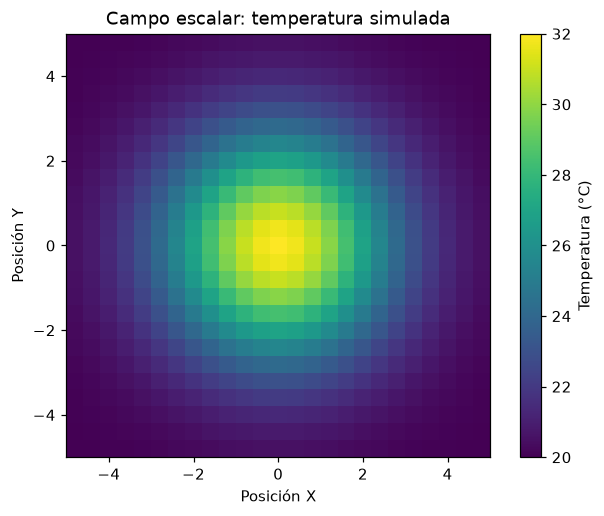

In [4]:
plt.figure(figsize=(7, 5))
mapa = plt.imshow(T, origin="lower", extent=[-5, 5, -5, 5],
                  cmap="viridis", vmin=20, vmax=32)
plt.colorbar(mapa, label="Temperatura (°C)")
plt.title("Campo escalar: temperatura simulada")
plt.xlabel("Posición X")
plt.ylabel("Posición Y")
plt.show()

**Resultado observado.** Apareció una región central amarilla (la más cálida de `viridis`) que se degradaba por verdes y azules hasta un violeta oscuro en los bordes. La barra de colores, de 20 a 32 °C, fue indispensable: sin ella el amarillo no habría significado nada cuantitativo.

**Comprobación del aprendizaje.** El gráfico representa la temperatura de cada posición como un color, y la variable que lo controla es el valor de `T` mapeado por la paleta entre `vmin=20` y `vmax=32`.

### Bloque 4. Dibujar isolíneas

**Qué se hizo.** Se trazaron con `plt.contour` cinco curvas de nivel (22, 24, 26, 28 y 30 °C), cada una rotulada con `clabel`. Una isolínea une todos los puntos con el mismo valor, igual que las curvas de nivel de un mapa topográfico. Se añadió `plt.axis("equal")` para que una unidad en X midiera lo mismo que una en Y y los círculos no se vieran deformados.

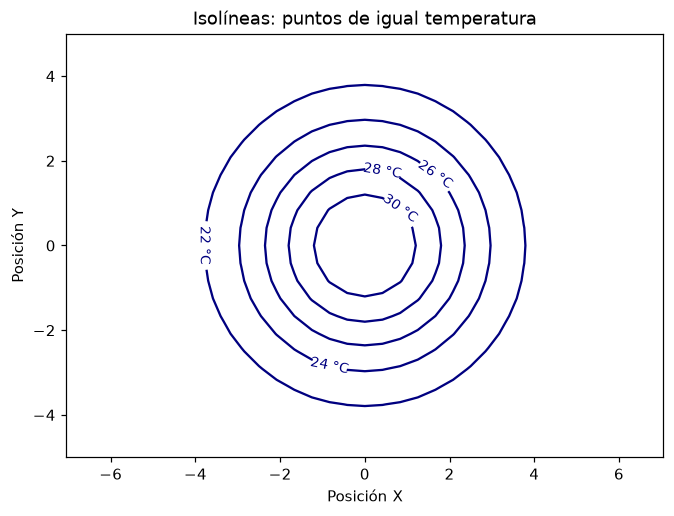

In [5]:
plt.figure(figsize=(7, 5))
lineas = plt.contour(X, Y, T, levels=[22, 24, 26, 28, 30],
                     colors="navy")
plt.clabel(lineas, inline=True, fontsize=9, fmt="%.0f °C")
plt.title("Isolíneas: puntos de igual temperatura")
plt.xlabel("Posición X")
plt.ylabel("Posición Y")
plt.axis("equal")
plt.show()

**Resultado observado.** Surgieron cinco circunferencias concéntricas. Que fueran círculos y no óvalos tiene explicación: `T` depende solo de `X² + Y²`, así que todos los puntos de igual temperatura equidistan del centro. Despejando la fórmula, la isolínea de 30 °C tiene radio ≈ 1,21 y la de 22 °C ≈ 3,79; las más cercanas entre sí (y por tanto las zonas de cambio más brusco) quedaron en la parte media del campo.

**Comprobación del aprendizaje.** El gráfico representa curvas que unen puntos de igual temperatura, y la variable que lo controla es la lista `levels`, que decide qué valores se dibujan.

### Bloque 5. Comparar dos mapas de colores

**Qué se hizo.** Se dibujó el mismo arreglo `T` dos veces, con las paletas `viridis` y `plasma`, y con idénticos `vmin` y `vmax`. El objetivo fue comprobar que cambiar los colores no cambia los datos, solo la forma de presentarlos.

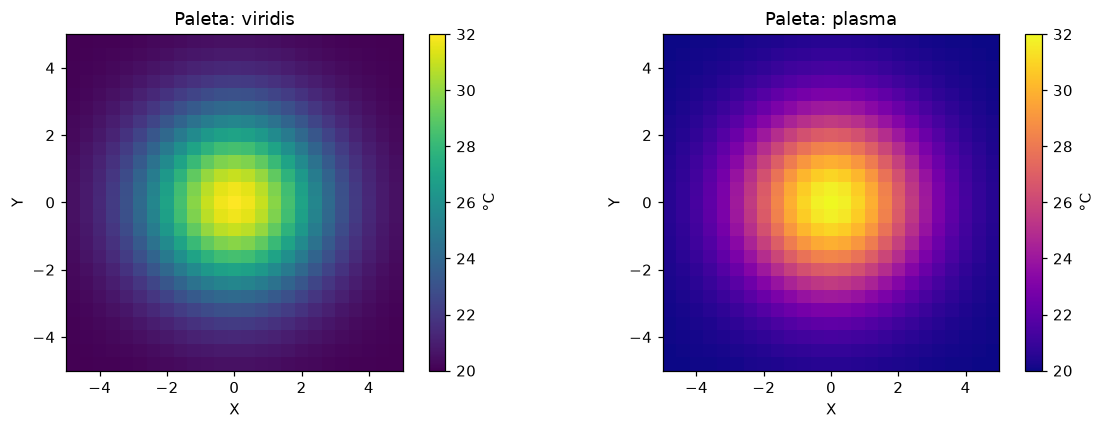

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, paleta in zip(axes, ["viridis", "plasma"]):
    imagen = ax.imshow(T, origin="lower", extent=[-5, 5, -5, 5],
                       cmap=paleta, vmin=20, vmax=32)
    ax.set_title("Paleta: " + paleta)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    fig.colorbar(imagen, ax=ax, label="°C")
plt.tight_layout()
plt.show()

**Resultado observado.** Ambos paneles mostraron exactamente el mismo patrón: un máximo central rodeado de un descenso radial. Solo cambió el aspecto (azul-verde-amarillo frente a púrpura-naranja-amarillo). Las dos son paletas secuenciales de luminosidad creciente, por eso en ambas el máximo se percibe como «lo más claro».

**Comprobación del aprendizaje.** Los gráficos representan los mismos 625 valores con distinta paleta, y la variable que cambia la apariencia es el argumento `cmap`, no los datos.

## 4. Retos resueltos individualmente

### Reto 1. Grilla de 25 a 50 puntos

**Enunciado.** Cambiar el número de puntos de la grilla de 25 a 50, usar `T[T.shape[0]//2, T.shape[1]//2]` como índice del centro y comparar la resolución.

Forma: (50, 50) | posiciones: 2500
Punto central T[c, c] -> 31.969 °C en ( 0.102 , 0.102 )
Máximo real de la grilla: 31.969 °C
Paso entre puntos -> 25: 0.417  | 50: 0.204


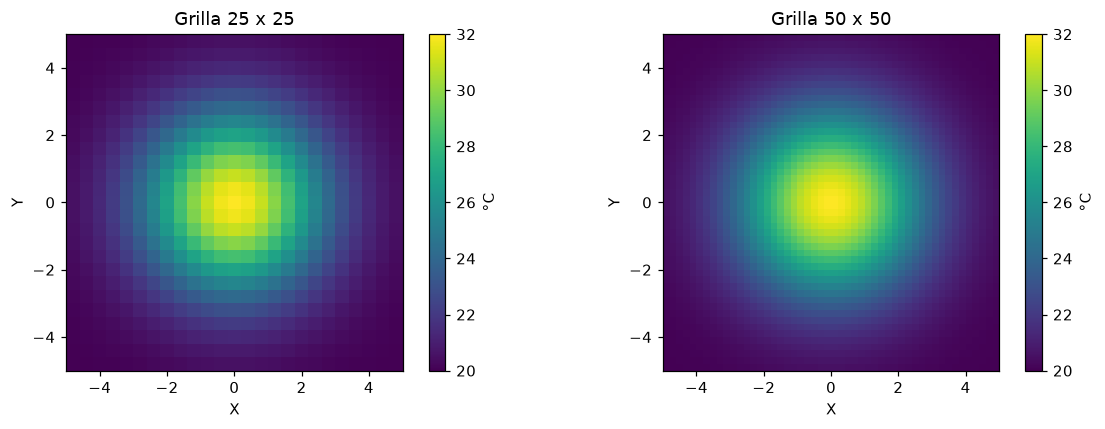

In [7]:
# Nueva grilla de 50 x 50 (2 500 posiciones) con la misma fórmula
x50 = np.linspace(-5, 5, 50)
y50 = np.linspace(-5, 5, 50)
X50, Y50 = np.meshgrid(x50, y50)
T50 = 20 + 12 * np.exp(-(X50**2 + Y50**2) / 8)

c = T50.shape[0] // 2          # índice "central" sin escribir un 12 a mano
print("Forma:", T50.shape, "| posiciones:", T50.size)
print("Punto central T[c, c] ->", round(T50[c, c], 3), "°C en (",
      round(X50[c, c], 3), ",", round(Y50[c, c], 3), ")")
print("Máximo real de la grilla:", round(T50.max(), 3), "°C")
print("Paso entre puntos -> 25:", round(10/24, 3), " | 50:", round(10/49, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, campo, titulo in zip(axes, [T, T50], ["Grilla 25 x 25", "Grilla 50 x 50"]):
    im = ax.imshow(campo, origin="lower", extent=[-5, 5, -5, 5],
                   cmap="viridis", vmin=20, vmax=32, interpolation="nearest")
    ax.set_title(titulo)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    fig.colorbar(im, ax=ax, label="°C")
plt.tight_layout()
plt.show()

**Análisis.** La grilla de 50 × 50 contuvo 2 500 posiciones y redujo el paso de 0,417 a 0,204 unidades, de modo que los «píxeles» del mapa se hicieron la mitad de grandes y el borde de la mancha se vio más suave. Hubo un detalle revelador: con 50 puntos (par) **ninguna posición cae en el origen**, y el punto «central» `T[25, 25]` quedó en (0,102; 0,102) con 31,969 °C, no 32. El máximo de 32 °C seguía existiendo en el campo continuo, pero la grilla ya no lo muestreaba. En síntesis: la resolución cambia lo que se ve, y el máximo observado depende de dónde caen las muestras.

### Reto 2. Cambiar el 12 por 18 en la fórmula

**Enunciado.** Reemplazar el coeficiente 12 por 18, generar nuevamente el mapa y explicar qué cambia.

Centro: 38.0 °C | máximo: 38.0 °C | mínimo: 20.03 °C
Celdas por encima de 32 °C (fuera de la escala original): 61 de 625


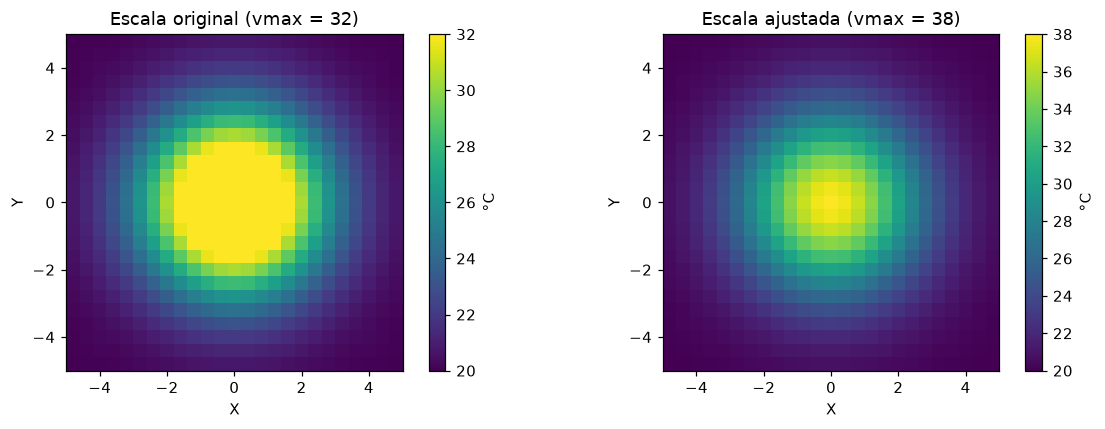

In [8]:
# Mismo campo, pero con amplitud 18 en lugar de 12
T18 = 20 + 18 * np.exp(-(X**2 + Y**2) / 8)

print("Centro:", round(T18[12, 12], 2), "°C | máximo:", round(T18.max(), 2),
      "°C | mínimo:", round(T18.min(), 2), "°C")
saturadas = int((T18 > 32).sum())
print("Celdas por encima de 32 °C (fuera de la escala original):", saturadas, "de", T18.size)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, vmax, titulo in zip(axes, [32, 38],
                            ["Escala original (vmax = 32)", "Escala ajustada (vmax = 38)"]):
    im = ax.imshow(T18, origin="lower", extent=[-5, 5, -5, 5],
                   cmap="viridis", vmin=20, vmax=vmax)
    ax.set_title(titulo)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    fig.colorbar(im, ax=ax, label="°C")
plt.tight_layout()
plt.show()

**Análisis.** El coeficiente 12 es la **amplitud** del punto caliente: al subirlo a 18, el centro pasó de 32 a 38 °C y la mancha se volvió más pronunciada, sin cambiar de ancho (el 8 del denominador es quien controla eso). Lo más relevante fue el panel izquierdo: como `vmax` seguía fijo en 32, las 61 celdas que superan ese valor se pintaron todas del mismo amarillo y el pico dejó de distinguirse de su entorno —**saturación de la paleta**—. Al ajustar `vmax=38` (panel derecho) el degradado completo reapareció. Una escala fija es útil para comparar mapas, pero debe cubrir el rango real de los datos.

### Reto 3. Seis isolíneas en lugar de cinco

**Enunciado.** Dibujar seis isolíneas en lugar de cinco y explicar qué información extra se observa.

22 °C -> radio 3.79
24 °C -> radio 2.96
26 °C -> radio 2.35
28 °C -> radio 1.80
30 °C -> radio 1.21
31 °C -> radio 0.83
Variación de temperatura por unidad de distancia entre isolíneas consecutivas:
  22 -> 24 °C: 2.43 °C/unidad
  24 -> 26 °C: 3.28 °C/unidad
  26 -> 28 °C: 3.61 °C/unidad
  28 -> 30 °C: 3.37 °C/unidad
  30 -> 31 °C: 2.68 °C/unidad


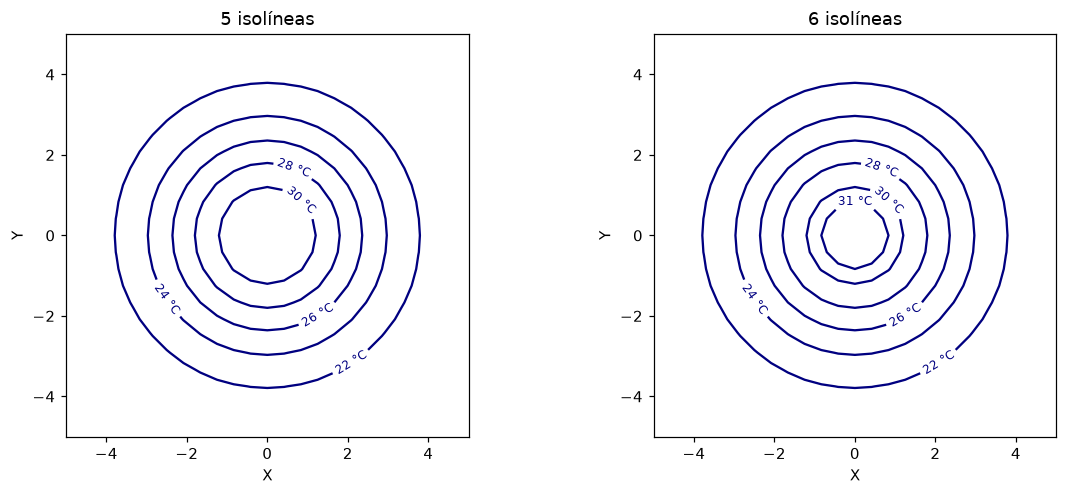

In [9]:
niveles6 = [22, 24, 26, 28, 30, 31]          # se añadió el nivel de 31 °C
radios = np.sqrt(8 * np.log(12 / (np.array(niveles6) - 20)))   # radio de cada círculo (despejado de la fórmula)

for nivel, radio in zip(niveles6, radios):
    print(f"{nivel} °C -> radio {radio:.2f}")
print("Variación de temperatura por unidad de distancia entre isolíneas consecutivas:")
for (n1, r1), (n2, r2) in zip(zip(niveles6, radios), zip(niveles6[1:], radios[1:])):
    print(f"  {n1} -> {n2} °C: {(n2 - n1) / (r1 - r2):.2f} °C/unidad")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, niveles, titulo in zip(axes, [[22, 24, 26, 28, 30], niveles6], ["5 isolíneas", "6 isolíneas"]):
    lineas = ax.contour(X, Y, T, levels=niveles, colors="navy")
    ax.clabel(lineas, inline=True, fontsize=8, fmt="%.0f °C")
    ax.set_title(titulo)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Análisis.** La sexta isolínea (31 °C, radio ≈ 0,83) añadió información sobre la **cima**, que con cinco líneas quedaba como un círculo vacío de radio 1,2. Además, la separación entre líneas consecutivas reveló la pendiente del campo: entre 28 y 30 °C la temperatura cambió ≈ 3,4 °C por unidad de distancia, mientras que entre 30 y 31 °C solo ≈ 2,7. Es decir, el campo es más empinado en la zona intermedia y se aplana hacia el centro, donde el máximo es una meseta suave y no un pico. Las isolíneas, por tanto, no solo marcan valores: sus distancias miden el gradiente.

## 5. Preguntas de interpretación

**1. ¿Por qué la temperatura en este ejemplo es un escalar y no un vector?**  
Porque cada posición almacena un único número (los °C) y ninguna dirección. Un vector necesitaría al menos dos componentes por punto; de este campo escalar sí podría derivarse uno (el gradiente, que apunta hacia donde más sube la temperatura), pero eso sería otro campo.

**2. ¿Qué significa la posición (X, Y) y qué significa el valor T?**  
(X, Y) es el lugar de la región donde se «mide»; T es el valor medido allí, la temperatura simulada en °C. La posición es el dominio del campo y T su valor.

**3. ¿Qué indica la barra de colores?**  
La correspondencia entre color y valor: de 20 °C (violeta) a 32 °C (amarillo). Sin ella el mapa solo permite comparar «más claro/más oscuro», no leer valores.

**4. ¿Por qué dos paletas diferentes representan los mismos datos?**  
Porque la paleta solo define cómo se traduce cada número en un color; el arreglo `T`, los límites y las posiciones son idénticos. Cambia la percepción, no la información.

**5. ¿Qué representa una isolínea de 28 °C?**  
El conjunto de puntos cuya temperatura es exactamente 28 °C; aquí, una circunferencia de radio ≈ 1,80 alrededor del centro. Dentro de ella hace más calor y fuera, menos.

## 6. Conclusiones

1. Un campo escalar asocia un solo valor a cada punto del espacio; por eso puede resumirse en una matriz y leerse como una superficie. Aprendí que el dato (la matriz T) es independiente de su representación: el mismo arreglo se mostró como mapa de calor, como isolíneas y con dos paletas, y en ningún caso cambió.

2. Interpreto los gráficos con tres cautelas que dejaron los retos: la barra de colores y sus límites deciden lo que se lee (un `vmax` mal elegido saturó el pico), la resolución de la grilla modifica el máximo observado, y las isolíneas informan además por su separación, que indica qué tan rápido cambia el campo. Un buen gráfico escalar necesita escala explícita, ejes de igual proporción y niveles elegidos con intención.